# Part 2 walkthrough: the production system, run small

This notebook follows the Part 2 system diagram from top to bottom. It runs real code on
a **600 m x 600 m area of Redfern** (between Redfern station and Redfern Park, crossing
Redfern, Surry Hills and Chippendale) and shows what each box produces.

![Part 2 system diagram](../docs/part2_diagram.png)

Each section starts by naming the diagram box, the production technology and the protocol
between systems. Production-only services are either replaced by a local equivalent with
the same interface, or shown as code without being run:

| Production | In this notebook |
|---|---|
| Apache Airflow | Same step functions called directly; the DAG is printed, not run |
| AWS Batch GPU job | DeepForest on CPU (36 chips, cached after the first run) |
| PostGIS | DuckDB with the spatial extension, same SQL |
| S3 | `data/s3/`, same key layout |
| FastAPI on containers behind CloudFront | The same FastAPI app called in-process with `TestClient` |
| Martin / pg_tileserv | The API's `/tiles/{z}/{x}/{y}.mvt` route |
| React + MapLibre GL | A standalone MapLibre GL page, `outputs/map.html` |

Every download is cached in `data/cache/`, so re-running the notebook takes seconds and
works offline.

In [1]:
import json
import logging
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from shapely.geometry import box

from pipeline import steps

from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("jpeg", pil_kwargs={"quality": 82})
pd.set_option("display.width", 140)
cx.set_cache_dir(str(steps.CACHE / "tiles"))

RUN_ID = MONTH = "2026-09"            # monthly run for September 2026
BBOX = steps.demo_area()              # 600 m x 600 m, lon/lat
CONTEXT_BBOX = steps.demo_area(1000)  # 2 km x 2 km for Sentinel-2 context
DEMO = gpd.GeoSeries([box(*BBOX)], crs=4326)


def aerial(ax, zoom=18):
    cx.add_basemap(ax, source=steps.SIX_TILE_URL, zoom=zoom, attribution="Imagery (c) NSW Spatial Services")
    ax.set_axis_off()


print("demo bbox:", BBOX)

demo bbox: (151.1997, -33.892857, 151.206299, -33.887543)


## 1. Data sources

**Diagram box:** Satellite imagery, Aerial and Lidar, Ground truth.
**Protocol:** HTTPS for everything: STAC (JSON) for Sentinel-2, the ArcGIS REST MapServer
`/export` endpoint for aerial imagery, and ArcGIS REST FeatureServer `/query` (GeoJSON) for the
council tree register and suburb boundaries. Endpoints and limits are listed in
[docs/data-access.md](../docs/data-access.md).

**Runs locally:** yes, these are the real public services.

First, the Sentinel-2 scenes for the month from the Earth Search STAC API (searched with `pystac-client`):

In [2]:
items = steps.search_sentinel(CONTEXT_BBOX, MONTH)
scenes = pd.DataFrame([{"scene": i.id, "date": i.datetime.date(), "tile cloud %": round(i.properties["eo:cloud_cover"], 1)}
                       for i in items])
print(f"{len(items)} Sentinel-2 L2A scenes in {MONTH} with < 80% cloud over the tile")
scenes

13 Sentinel-2 L2A scenes in 2026-09 with < 80% cloud over the tile


,scene,date,tile cloud %
0,S2C_56HLH_20260901_0_L2A,2026-09-01,62.9
1,S2A_56HLH_20260903_0_L2A,2026-09-03,0.2
2,S2C_56HLH_20260905_0_L2A,2026-09-05,28.0
3,S2B_56HLH_20260906_0_L2A,2026-09-06,2.3
4,S2B_56HLH_20260910_0_L2A,2026-09-10,60.0
5,S2C_56HLH_20260911_0_L2A,2026-09-11,15.6
6,S2C_56HLH_20260915_0_L2A,2026-09-15,4.7
7,S2B_56HLH_20260916_0_L2A,2026-09-16,59.0
8,S2A_56HLH_20260917_0_L2A,2026-09-17,38.1
9,S2B_56HLH_20260920_0_L2A,2026-09-20,0.0


Next, NSW aerial imagery from SIX Maps. The area is split into 36 chips of 100 m, each
requested with a 10 m margin at 10 cm per pixel (1,200 x 1,200 px). That is close to the
resolution the detection model was trained on.

36 chips, 1200 x 1200 px each, cached in data\cache\aerial\b6bf4df5


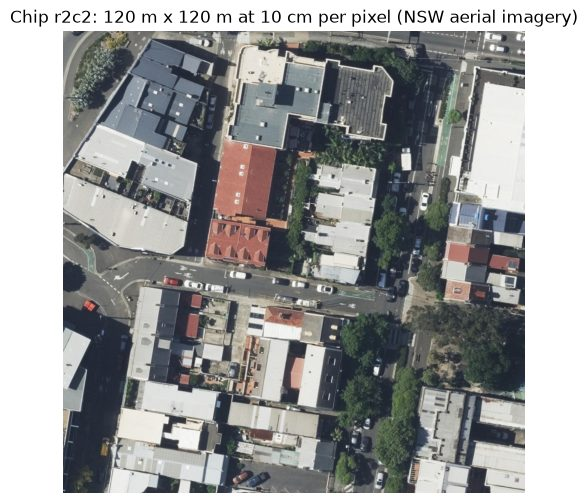

In [3]:
chips = steps.fetch_aerial_chips(BBOX)
print(f"{len(chips)} chips, {chips.px.iloc[0]} x {chips.px.iloc[0]} px each, cached in {Path(chips.path.iloc[0]).parent.relative_to(ROOT)}")

sample = chips.set_index("chip_id").loc["r2c2"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(plt.imread(sample.path))
ax.set_title("Chip r2c2: 120 m x 120 m at 10 cm per pixel (NSW aerial imagery)")
ax.set_axis_off()

Finally, the ground truth: City of Sydney tree register points and NSW suburb boundaries
(clipped to the demo area).

649 register trees in the demo area


,register trees
TreeType,
Street Tree,468
Park Tree,181


,suburb,postcode,area_ha
0,Redfern,2016,24.50
1,Chippendale,2008,4.64
2,Surry Hills,2010,6.84


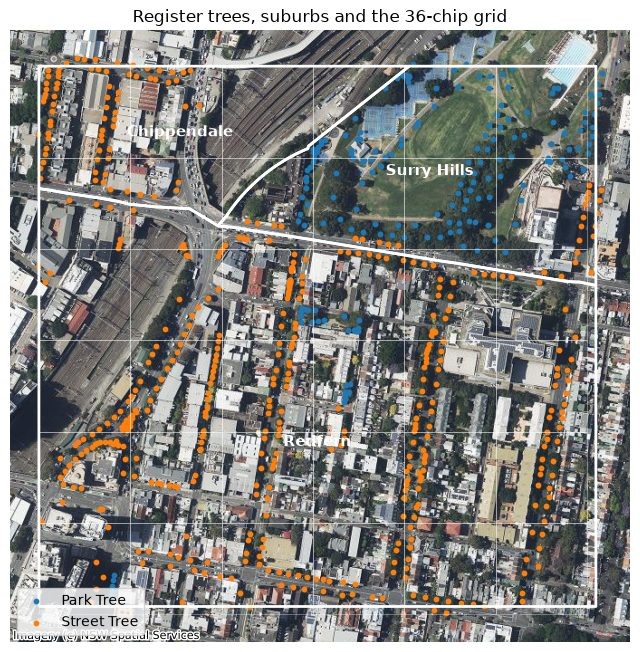

In [4]:
register = steps.load_register(BBOX)
suburbs = steps.load_suburbs(BBOX)
print(f"{len(register)} register trees in the demo area")
display(register["TreeType"].value_counts().rename("register trees").to_frame())
display(suburbs.drop(columns="geometry"))

fig, ax = plt.subplots(figsize=(8, 8))
suburbs.to_crs(3857).boundary.plot(ax=ax, color="white", linewidth=2)
chips.boundary.plot(ax=ax, color="white", linewidth=0.4, alpha=0.6)
register.to_crs(3857).plot(ax=ax, column="TreeType", markersize=10, legend=True,
                           legend_kwds={"loc": "lower left"})
for s in suburbs.to_crs(3857).itertuples():
    p = s.geometry.representative_point()
    ax.annotate(s.suburb, (p.x, p.y), color="white", weight="bold", ha="center", fontsize=11)
aerial(ax, zoom=17)
ax.set_title("Register trees, suburbs and the 36-chip grid")
plt.show()

## 2. Ingestion and orchestration

**Diagram box:** Ingestion and orchestration.
**Production:** Apache Airflow runs a monthly DAG. `rasterio` reads only the needed window of
each Sentinel-2 Cloud-Optimised GeoTIFF using HTTP range requests, so a 2 km window downloads
a few hundred KB rather than the whole 100 km tile. Clouds are masked with the Sentinel-2 Scene
Classification Layer (SCL), and the result is written to S3 as a COG.
**Runs locally:** the step functions run for real and write to `data/s3/`, a local folder with the same layout as the S3 bucket.

The scene table shows the cloud cover the catalogue reports for the whole tile, next to the share of
pixels actually masked in our 2 km window:

In [5]:
ndvi = steps.make_ndvi_cog(items, CONTEXT_BBOX, MONTH)
table = pd.DataFrame([{k: s[k] for k in ("date", "tile_cloud_pct", "local_masked_pct")} for s in ndvi.scenes])
print("masked SCL classes:", ", ".join(steps.SCL_MASK.values()))
table

masked SCL classes: no data, saturated, cloud shadow, cloud (medium), cloud (high), cirrus


,date,tile_cloud_pct,local_masked_pct
0,2026-09-01,62.9,17.8
1,2026-09-03,0.2,0.0
2,2026-09-05,28.0,0.0
3,2026-09-06,2.3,0.0
4,2026-09-10,60.0,100.0
5,2026-09-11,15.6,0.0
6,2026-09-15,4.7,0.0
7,2026-09-16,59.0,100.0
8,2026-09-17,38.1,100.0
9,2026-09-20,0.0,0.0


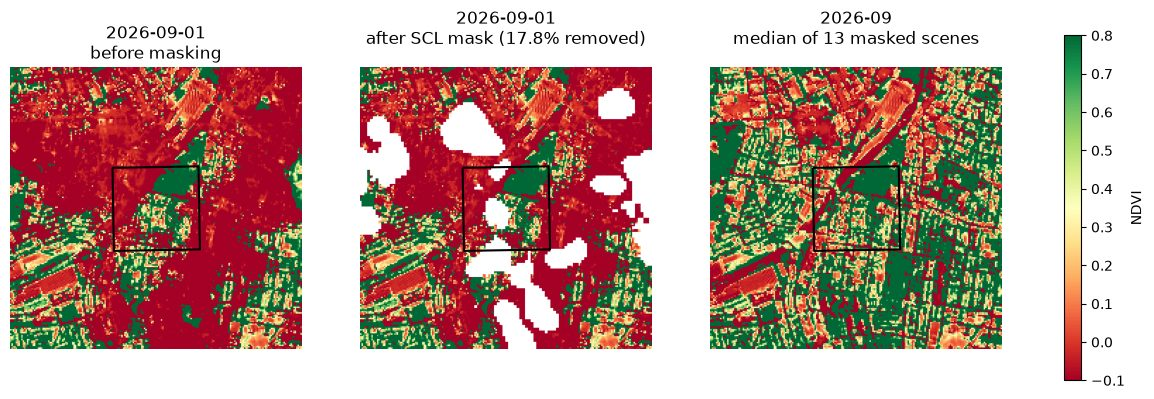

written: data\s3\raw\sentinel2\2026-09\ndvi_median.tif
driver: GTiff | tiled: True | layout: COG | crs: EPSG:32756 | size: 207 x 200


In [6]:
import rasterio
from rasterio.plot import plotting_extent

demo_native = DEMO.to_crs(ndvi.crs)
shown = max((s for s in ndvi.scenes if s["local_masked_pct"] < 90), key=lambda s: s["local_masked_pct"])
extent = plotting_extent(ndvi.composite, ndvi.transform)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
panels = [(shown["ndvi_raw"], f"{shown['date']}\nbefore masking"),
          (shown["ndvi_masked"], f"{shown['date']}\nafter SCL mask ({shown['local_masked_pct']}% removed)"),
          (ndvi.composite, f"{MONTH}\nmedian of {len(ndvi.scenes)} masked scenes")]
for ax, (img, title) in zip(axes, panels):
    im = ax.imshow(img, cmap="RdYlGn", vmin=-0.1, vmax=0.8, extent=extent)
    demo_native.boundary.plot(ax=ax, color="black", linewidth=1.5)
    ax.set_title(title)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.8, label="NDVI")
plt.show()

with rasterio.open(ndvi.path) as src:
    print("written:", ndvi.path.relative_to(ROOT))
    print("driver:", src.driver, "| tiled:", src.profile.get("tiled"), "| layout:", src.tags(ns="IMAGE_STRUCTURE").get("LAYOUT"),
          "| crs:", src.crs, "| size:", src.width, "x", src.height)

Sentinel-2 at 10 m cannot separate individual trees, but it is free, arrives every five days
and is used in production to flag change (canopy lost or gained since last month) and to decide
where new aerial imagery is worth processing. The black square is the demo area; trees are counted
from the aerial imagery in section 3.

In production Airflow schedules these same functions. The DAG below imports `pipeline/steps.py`.
It is shown here but not run, because Airflow does not run natively on Windows. The QA gate is a
`ShortCircuitOperator`: if validation fails, `publish` is skipped and nothing reaches the public.

In [7]:
print((ROOT / "pipeline" / "dag.py").read_text())

"""Airflow DAG: monthly Sydney tree count.

Wraps the functions in `pipeline/steps.py` as tasks. Tasks pass S3 keys to each
other through XCom, never data. In production `detect` is dispatched to an AWS Batch
GPU queue and `publish` writes to PostGIS and S3 instead of the local stand-ins.

Shown in the notebook, not run locally (Airflow does not run natively on Windows).
"""

from __future__ import annotations

from datetime import datetime, timedelta

import geopandas as gpd
from airflow.decorators import dag, task
from airflow.operators.python import ShortCircuitOperator

from pipeline import steps

BBOX = steps.demo_area()
CONTEXT_BBOX = steps.demo_area(1000)


def month_of(data_interval_start) -> str:
    return data_interval_start.strftime("%Y-%m")


@dag(
    dag_id="sydney_tree_count",
    schedule="0 3 2 * *",  # 03:00 on the 2nd: last month's scenes are in the catalogue by then
    start_date=datetime(2026, 1, 1),
    catchup=False,
    max_active_runs=1,
    default_args={"re

## 3. Tree detection model

**Diagram box:** Tree detection model.
**Production:** a PyTorch model (DeepForest, a RetinaNet trained on 10 cm aerial imagery) runs as
an AWS Batch job on a rented GPU. It reads chips from S3 and writes one crown per tree.
**Runs locally:** the same model on CPU. Each chip took about 13 s on first run; the results are cached per chip.

Each chip is split into 800 px patches (80 m), which the model rescales to its 400 px input.
DeepForest was trained on forest imagery where crowns are smaller than Sydney's street and park
trees. With 400 px patches it split large crowns into several small boxes; 800 px gives one box per crown.
A detection is kept if its score is at least 0.2 (chosen in section 4) and its centre lies in the
chip's 100 m core, so trees in the overlap margin are not counted twice.

In [8]:
SCORE_THRESHOLD = 0.2
trees = steps.detect_trees(chips, score_threshold=SCORE_THRESHOLD)
print(f"{len(trees):,} trees detected in {DEMO.to_crs(steps.METRIC_CRS).area.iloc[0] / 1e4:.0f} ha")
trees[["score", "crown_area_m2", "crown_diameter_m"]].describe().round(2).T

673 trees detected in 36 ha


,count,mean,std,min,25%,50%,75%,max
score,673.0,0.40,0.15,0.2,0.26,0.36,0.51,0.81
crown_area_m2,673.0,78.28,98.54,4.9,26.90,46.70,83.50,939.90
crown_diameter_m,673.0,7.84,4.10,2.2,5.20,6.80,9.10,30.70


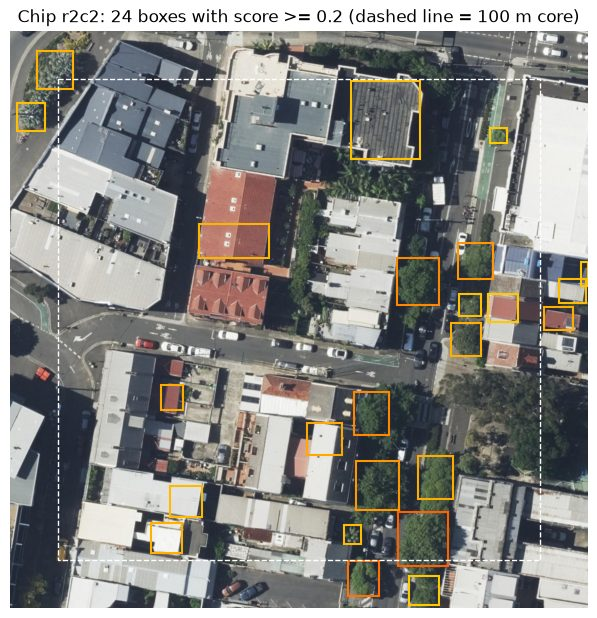

In [9]:
raw = steps.predict_chip(sample.path)
kept = raw[raw.score >= SCORE_THRESHOLD]

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(plt.imread(sample.path))
for d in kept.itertuples():
    ax.add_patch(plt.Rectangle((d.xmin, d.ymin), d.xmax - d.xmin, d.ymax - d.ymin, fill=False,
                               edgecolor=plt.cm.autumn_r(d.score), linewidth=1.5))
margin = 100  # 10 m margin at 10 cm per pixel
ax.add_patch(plt.Rectangle((margin, margin), sample.px - 2 * margin, sample.px - 2 * margin, fill=False,
                           edgecolor="white", linestyle="--", linewidth=1))
ax.set_title(f"Chip r2c2: {len(kept)} boxes with score >= {SCORE_THRESHOLD} (dashed line = 100 m core)")
ax.set_axis_off()

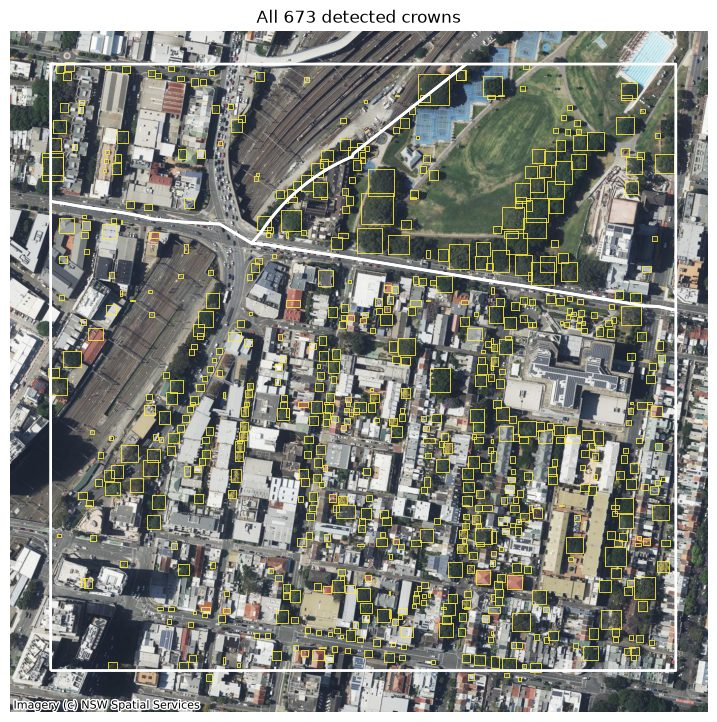

In [10]:
fig, ax = plt.subplots(figsize=(9, 9))
trees.to_crs(3857).boundary.plot(ax=ax, color="#ffeb3b", linewidth=0.6)
suburbs.to_crs(3857).boundary.plot(ax=ax, color="white", linewidth=2)
aerial(ax, zoom=18)
ax.set_title(f"All {len(trees):,} detected crowns")
plt.show()

## 4. Validation and QA

**Diagram box:** Validation and QA.
**Production:** GeoPandas compares every run with the council register before anything is published.
**Runs locally:** yes.

Each register tree is matched to the nearest detected crown centre within 5 m (`sjoin_nearest`),
with each detection used once. The register records the trunk and the model the crown centre; with
crowns about 7 m across, those are often a few metres apart. **Recall** is the share of register
trees that were found. **Precision** is measured only near register trees, because the register covers
public land only: a correct detection of a backyard tree would otherwise count as a false positive.
In production, precision on private land would come from a sample of hand-counted plots.

In [11]:
v = steps.validate(trees, register, match_m=5.0)
pd.Series(v.as_dict()).to_frame("value")

,value
precision,0.897
recall,0.418
f1,0.570
matched,271.000
register_trees,649.000
detections_in_zone,302.000
match_m,5.000


In [12]:
sweep = []
for t in (0.1, 0.15, 0.2, 0.25, 0.3, 0.4):
    detected = steps.detect_trees(chips, score_threshold=t)
    m = steps.validate(detected, register).as_dict()
    sweep.append({"score threshold": t, "trees detected": len(detected), "near register": m["detections_in_zone"],
                  "precision": m["precision"], "recall": m["recall"], "f1": m["f1"]})
pd.DataFrame(sweep).set_index("score threshold")

,trees detected,near register,precision,recall,f1
score threshold,,,,,
0.10,1156,386,0.845,0.502,0.630
0.15,855,331,0.882,0.450,0.596
0.20,673,302,0.897,0.418,0.570
0.25,538,267,0.910,0.374,0.531
0.30,436,237,0.924,0.337,0.494
0.40,286,182,0.945,0.265,0.414


**Choosing the threshold.** Lowering the threshold below 0.2 adds detections quickly (the total nearly
doubles by 0.1) but recall improves only slowly. That suggests most of the extra boxes are not trees
(roofs, shrubs) in places the register cannot check. So 0.2 is used, where precision near register trees is about 0.9.

**Where recall is lost.** Recall depends strongly on tree size. Small, young street trees are often
hidden under a neighbour's canopy or are too small to see, and rows of touching crowns can merge
into one box:

In [13]:
found = register["asset_id"].isin(v.matches["asset_id"])
height = pd.cut(register["TreeHeight"], [0, 5, 8, 12, 100], labels=["under 5 m", "5-8 m", "8-12 m", "12 m+"])
pd.DataFrame({"register trees": found.groupby(height).size(), "recall": found.groupby(height).mean().round(2)}).T

TreeHeight,under 5 m,5-8 m,8-12 m,12 m+
register trees,149.00,172.00,137.00,191.00
recall,0.15,0.42,0.53,0.54


This is the main limitation of an off-the-shelf model on aerial imagery alone. In production it is
addressed by fine-tuning on the council register and adding a lidar canopy height model (box 1, ELVIS).
The published count is the detected count; the recall figures are published with every run so users can
judge how complete it is.

**The QA gate.** The production thresholds (precision of at least 0.8, recall of at least 0.4) sit just below this
baseline run, so the gate catches drift such as bad imagery or a broken model release. The run passes.
With a deliberately strict threshold the same run is blocked and nothing would be published.

In [14]:
passed = steps.qa_gate(v)
_ = steps.qa_gate(v, min_precision=0.9, min_recall=0.9)

QA gate: PASS - precision 0.90 >= 0.80, recall 0.42 >= 0.40
QA gate: BLOCKED - precision 0.90 < 0.90; recall 0.42 < 0.90 - nothing is published


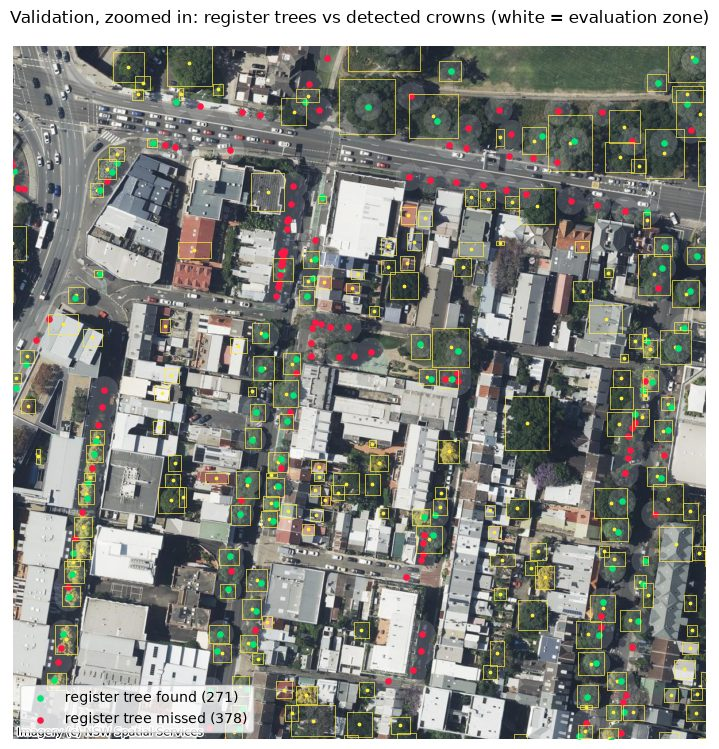

In [15]:
reg_m = register.to_crs(3857)
matched = reg_m["asset_id"].isin(v.matches["asset_id"])
centres = trees.to_crs(steps.METRIC_CRS).centroid.to_crs(3857)

fig, ax = plt.subplots(figsize=(9, 9))
gpd.GeoSeries(v.zone.to_crs(3857)).plot(ax=ax, color="white", alpha=0.15)
trees.to_crs(3857).boundary.plot(ax=ax, color="#ffeb3b", linewidth=0.5)
centres.plot(ax=ax, color="#ffeb3b", markersize=3)
reg_m[matched].plot(ax=ax, color="#00e676", markersize=14, label=f"register tree found ({matched.sum()})")
reg_m[~matched].plot(ax=ax, color="#ff1744", markersize=14, label=f"register tree missed ({(~matched).sum()})")
ax.legend(loc="lower left")
xmin, ymin, xmax, ymax = reg_m.total_bounds
cx_, cy_ = (xmin + xmax) / 2, (ymin + ymax) / 2
ax.set_xlim(cx_ - 180, cx_ + 180)
ax.set_ylim(cy_ - 180, cy_ + 180)
aerial(ax, zoom=19)
ax.set_title("Validation, zoomed in: register trees vs detected crowns (white = evaluation zone)")
plt.show()

## 5. Storage

**Diagram box:** Spatial database and Object storage.
**Production:** PostGIS holds the trees, suburbs and run history; S3 holds a GeoParquet snapshot per month.
**Runs locally:** DuckDB with the spatial extension stands in for PostGIS, and `data/s3/` for S3.
The SQL uses only functions both have (`ST_Within`, `ST_Centroid`, `ST_MakeEnvelope`,
`ST_Intersects`), so it runs unchanged on PostGIS. There you would also add
`CREATE INDEX ON trees USING GIST (geom)`.

Blocked runs are still recorded in `runs` (for monitoring), but their trees are not stored.

In [16]:
result = steps.store_run(RUN_ID, trees, suburbs, v, passed)
print("database:", result["db"].relative_to(ROOT))
print("snapshot:", result["snapshot"].relative_to(ROOT))
print(steps.SUBURB_STATS_SQL)

database: data\store.duckdb
snapshot: data\s3\snapshots\2026-09\trees.parquet

CREATE OR REPLACE VIEW suburb_stats AS
WITH latest AS (
    SELECT run_id FROM runs WHERE passed ORDER BY run_at DESC LIMIT 1
)
SELECT s.suburb,
       s.postcode,
       s.area_ha,
       COUNT(t.tree_id)                                         AS trees,
       ROUND(COUNT(t.tree_id) / s.area_ha, 1)                   AS trees_per_ha,
       ROUND(COALESCE(SUM(t.crown_area_m2), 0) / (s.area_ha * 100), 1) AS crown_cover_pct,
       (SELECT run_id FROM latest)                              AS run_id
FROM suburbs s
LEFT JOIN trees t
       ON t.run_id = (SELECT run_id FROM latest)
      AND ST_Within(ST_Centroid(t.geom), s.geom)
GROUP BY s.suburb, s.postcode, s.area_ha
ORDER BY trees DESC



In [17]:
con = steps.connect(read_only=True)
display(con.sql("SELECT 'runs' AS tbl, COUNT(*) AS n FROM runs UNION ALL SELECT 'suburbs', COUNT(*) FROM suburbs "
                "UNION ALL SELECT 'trees', COUNT(*) FROM trees").df())
display(con.sql("SELECT * FROM runs").df())
stats = con.sql("SELECT * FROM suburb_stats").df()
con.close()
stats

,tbl,n
0,runs,1
1,suburbs,3
2,trees,673


,run_id,run_at,imagery,n_trees,precision,recall,passed
0,2026-09,2026-10-09 13:34:28.481143,NSW aerial (SIX Maps),673,0.897,0.418,True


,suburb,postcode,area_ha,trees,trees_per_ha,crown_cover_pct,run_id
0,Redfern,2016,24.50,517,21.1,13.5,2026-09
1,Surry Hills,2010,6.84,98,14.3,21.4,2026-09
2,Chippendale,2008,4.64,54,11.6,10.4,2026-09


In [18]:
snap = gpd.read_parquet(result["snapshot"])
import pyarrow.parquet as pq
geo = json.loads(pq.read_schema(result["snapshot"]).metadata[b"geo"])
print(f"GeoParquet snapshot: {len(snap):,} rows, geometry column '{geo['primary_column']}', "
      f"encoding {geo['columns'][geo['primary_column']]['encoding']}")
snap.head(3)

GeoParquet snapshot: 673 rows, geometry column 'geometry', encoding WKB


,tree_id,chip_id,score,geometry,crown_area_m2,crown_diameter_m,run_id
0,T000000,r0c0,0.580,"POLYGON ((151.19995 -33.88761, 151.19995 -33.8...",81.7,9.0,2026-09
1,T000001,r0c0,0.450,"POLYGON ((151.2008 -33.88765, 151.2008 -33.887...",41.9,6.5,2026-09
2,T000002,r0c0,0.437,"POLYGON ((151.20051 -33.88823, 151.20051 -33.8...",127.0,11.3,2026-09


## 6. API and tiles

**Diagram box:** API and tile service.
**Production:** FastAPI (REST/JSON and GeoJSON) on containers, plus Martin or pg_tileserv for
vector tiles, all behind the CloudFront CDN. The API sets `Cache-Control` headers, so the CDN
answers almost every request and the database is only queried once per URL per day.
**Runs locally:** the same FastAPI app (`api/main.py`), called in-process with FastAPI's `TestClient` instead of over the network.

In [19]:
from fastapi.testclient import TestClient
from api.main import app

client = TestClient(app)
print("routes:", ", ".join(r.path for r in app.routes if not r.path.startswith(("/docs", "/redoc", "/openapi"))))

r = client.get("/suburbs")
print("\nGET /suburbs ->", r.status_code, "| Cache-Control:", r.headers["cache-control"])
print(json.dumps(r.json(), indent=2))

routes: /runs, /suburbs, /suburbs/{name}, /trees, /, /conformance, /collections, /collections/{cid}, /collections/{cid}/items, /tiles/{z}/{x}/{y}.mvt



GET /suburbs -> 200 | Cache-Control: public, max-age=300, s-maxage=86400, stale-while-revalidate=3600
[
  {
    "suburb": "Redfern",
    "postcode": 2016,
    "area_ha": 24.5,
    "trees": 517,
    "trees_per_ha": 21.1,
    "crown_cover_pct": 13.5,
    "run_id": "2026-09"
  },
  {
    "suburb": "Surry Hills",
    "postcode": 2010,
    "area_ha": 6.84,
    "trees": 98,
    "trees_per_ha": 14.3,
    "crown_cover_pct": 21.4,
    "run_id": "2026-09"
  },
  {
    "suburb": "Chippendale",
    "postcode": 2008,
    "area_ha": 4.64,
    "trees": 54,
    "trees_per_ha": 11.6,
    "crown_cover_pct": 10.4,
    "run_id": "2026-09"
  }
]


Vector tiles are what the web map draws. The tile below is encoded by the API, then decoded again
to show what a browser receives: a compact binary tile with a `trees` layer and a `suburbs` layer.

GET /tiles/17/120587/78664.mvt -> 200 | application/vnd.mapbox-vector-tile | 10,761 bytes | Cache-Control: public, max-age=3600, s-maxage=604800
  layer 'trees': 168 features, extent 4096, first properties {'tree_id': 'T000097', 'score': 0.746, 'crown_area_m2': 45.4}
  layer 'suburbs': 3 features, extent 4096, first properties {'suburb': 'Redfern', 'trees': 517, 'trees_per_ha': 21.1, 'crown_cover_pct': 13.5}


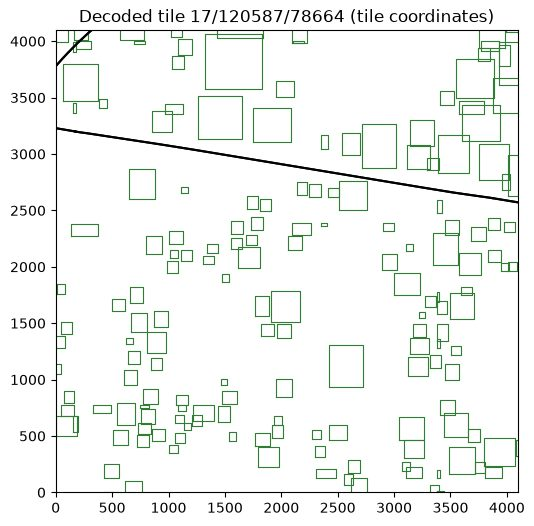

In [20]:
import mapbox_vector_tile
import mercantile

lon, lat = (BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2
t = mercantile.tile(lon, lat, 17)
r = client.get(f"/tiles/{t.z}/{t.x}/{t.y}.mvt")
print(f"GET /tiles/{t.z}/{t.x}/{t.y}.mvt ->", r.status_code, "|", r.headers["content-type"], "|",
      f"{len(r.content):,} bytes | Cache-Control: {r.headers['cache-control']}")

decoded = mapbox_vector_tile.decode(r.content)
for name, layer in decoded.items():
    print(f"  layer '{name}': {len(layer['features'])} features, extent {layer['extent']}, "
          f"first properties {layer['features'][0]['properties']}")

fig, ax = plt.subplots(figsize=(6, 6))
for f in decoded["trees"]["features"]:
    for ring in f["geometry"]["coordinates"]:
        xs, ys = zip(*ring)
        ax.plot(xs, ys, color="#2e7d32", linewidth=0.8)
for f in decoded["suburbs"]["features"]:
    polys = f["geometry"]["coordinates"] if f["geometry"]["type"] == "MultiPolygon" else [f["geometry"]["coordinates"]]
    for poly in polys:
        xs, ys = zip(*poly[0])
        ax.plot(xs, ys, color="black", linewidth=1.5)
ax.set_xlim(0, 4096); ax.set_ylim(0, 4096); ax.set_aspect("equal")
ax.set_title(f"Decoded tile {t.z}/{t.x}/{t.y} (tile coordinates)")
plt.show()

## 7. Web map

**Diagram box:** Web map.
**Production:** a React app using MapLibre GL, reading vector tiles from the CDN.
**Runs locally:** `outputs/map.html`, a standalone MapLibre GL page with the same layers (a suburb
choropleth and tree crowns over NSW aerial imagery). It embeds the data, so it opens straight from disk.
Open it in a browser to pan, zoom and click a suburb. A static PNG of the same view is shown below so it is visible on GitHub.

web map: outputs\map.html (204 KB)


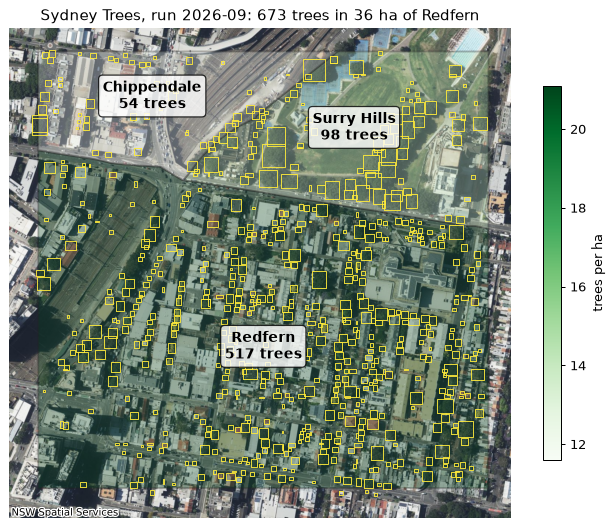

In [21]:
from pipeline.webmap import write_map_png, write_web_map

suburb_stats = steps.suburb_stats_gdf()
html = write_web_map(RUN_ID, trees, suburb_stats, ROOT / "outputs" / "map.html")
png = write_map_png(RUN_ID, trees, suburb_stats, ROOT / "outputs" / "map.png")
print("web map:", html.relative_to(ROOT), f"({html.stat().st_size / 1e3:.0f} KB)")
display(Image(filename=str(png), width=760))

## 8. Open data

**Diagram box:** Open data.
**Production:** after every published run the files are written to a public S3 bucket behind the
CDN. Each run has a permanent URL, and `latest.json` always points at the newest run.
**Runs locally:** files are written to `outputs/open-data/`.

In [22]:
export = steps.export_open_data(RUN_ID, trees, suburb_stats)
files = sorted(export["folder"].iterdir())
display(pd.DataFrame({"file": [f.name for f in files], "KB": [round(f.stat().st_size / 1e3, 1) for f in files]}))
print(json.dumps(export["latest"], indent=2))

,file,KB
0,suburbs.csv,0.2
1,suburbs.geojson,5.5
2,trees.csv,41.2
3,trees.geojson,252.0
4,trees.parquet,49.3


{
  "run_id": "2026-09",
  "published_at": "2026-10-09T13:34:33+00:00",
  "n_trees": 673,
  "files": {
    "trees.geojson": "https://data.example.org/sydney-trees/2026-09/trees.geojson",
    "trees.csv": "https://data.example.org/sydney-trees/2026-09/trees.csv",
    "trees.parquet": "https://data.example.org/sydney-trees/2026-09/trees.parquet",
    "suburbs.geojson": "https://data.example.org/sydney-trees/2026-09/suburbs.geojson",
    "suburbs.csv": "https://data.example.org/sydney-trees/2026-09/suburbs.csv"
  },
  "licence": "CC BY 4.0"
}


In [23]:
back = gpd.read_file(export["folder"] / "trees.geojson")
csv = pd.read_csv(export["folder"] / "trees.csv")
print(f"trees.geojson reads back: {len(back):,} features, CRS {back.crs}")
print(f"trees.csv reads back: {len(csv):,} rows")
csv.head()

trees.geojson reads back: 673 features, CRS EPSG:4326
trees.csv reads back: 673 rows


,tree_id,chip_id,score,crown_area_m2,crown_diameter_m,lon,lat,run_id
0,T000000,r0c0,0.580,81.7,9.0,151.199902,-33.887566,2026-09
1,T000001,r0c0,0.450,41.9,6.5,151.200761,-33.887623,2026-09
2,T000002,r0c0,0.437,127.0,11.3,151.200457,-33.888180,2026-09
3,T000003,r0c0,0.436,60.6,7.8,151.199843,-33.887923,2026-09
4,T000004,r0c0,0.428,168.5,13.0,151.199794,-33.888092,2026-09


## 9. Public API

**Diagram box:** Public API.
**Production:** the same FastAPI service, documented with OpenAPI, over HTTPS. Other apps can ask for
"trees in this bounding box" as GeoJSON. GIS software such as QGIS and ArcGIS can connect through the
OGC API Features endpoints (the modern successor to WFS): in QGIS, *Layer > Add Layer > Add WFS / OGC API
Features Layer*, then enter the API's base URL.
**Runs locally:** the same calls through `TestClient`. The `curl` lines show the production equivalents.

In [24]:
API = "https://api.example.org/sydney-trees"
small = (151.2025, -33.8915, 151.2035, -33.8905)
bbox = ",".join(map(str, small))

print(f"$ curl '{API}/trees?bbox={bbox}'")
r = client.get("/trees", params={"bbox": bbox})
fc = r.json()
print(r.status_code, r.headers["content-type"], "|", fc["numberMatched"], "trees in the box")
first = fc["features"][0]
print(json.dumps({"type": first["type"], "id": first["id"],
                  "geometry": {"type": first["geometry"]["type"],
                               "coordinates": [[[round(x, 6), round(y, 6)] for x, y in first["geometry"]["coordinates"][0]]]},
                  "properties": first["properties"]}, indent=1))

$ curl 'https://api.example.org/sydney-trees/trees?bbox=151.2025,-33.8915,151.2035,-33.8905'


200 application/geo+json | 37 trees in the box
{
 "type": "Feature",
 "id": "T000325",
 "geometry": {
  "type": "Polygon",
  "coordinates": [
   [
    [
     151.202518,
     -33.890706
    ],
    [
     151.202518,
     -33.89063
    ],
    [
     151.202427,
     -33.89063
    ],
    [
     151.202427,
     -33.890706
    ],
    [
     151.202518,
     -33.890706
    ]
   ]
  ]
 },
 "properties": {
  "tree_id": "T000325",
  "run_id": "2026-09",
  "score": 0.644,
  "crown_area_m2": 71.2,
  "crown_diameter_m": 8.4
 }
}


In [25]:
print(f"$ curl '{API}/collections/trees/items?limit=2'")
r = client.get("/collections/trees/items", params={"limit": 2})
body = r.json()
print(r.status_code, r.headers["content-type"])
print(json.dumps({k: body[k] for k in ("type", "numberMatched", "numberReturned", "links")}, indent=2))

print(f"\n$ curl '{API}/conformance'")
print(json.dumps(client.get("/conformance").json(), indent=2))

$ curl 'https://api.example.org/sydney-trees/collections/trees/items?limit=2'


200 application/geo+json
{
  "type": "FeatureCollection",
  "numberMatched": 673,
  "numberReturned": 2,
  "links": [
    {
      "href": "http://testserver/collections/trees/items?limit=2&offset=0",
      "rel": "self",
      "type": "application/geo+json"
    },
    {
      "href": "http://testserver/collections/trees/items?limit=2&offset=2",
      "rel": "next",
      "type": "application/geo+json"
    }
  ]
}

$ curl 'https://api.example.org/sydney-trees/conformance'
{
  "conformsTo": [
    "http://www.opengis.net/spec/ogcapi-features-1/1.0/conf/core",
    "http://www.opengis.net/spec/ogcapi-features-1/1.0/conf/geojson"
  ]
}


## Wrap-up: from this notebook to production

| Diagram box | In this notebook | In production |
|---|---|---|
| Ingestion and orchestration | Step functions called in order; `pipeline/dag.py` printed | Airflow (MWAA or containerised) runs `sydney_tree_count` monthly |
| Tree detection model | DeepForest on CPU, 36 chips | Same container on AWS Batch GPU (spot), chips listed from S3 |
| Validation and QA | `validate()` + `qa_gate()` | Same functions; `ShortCircuitOperator` blocks `publish` |
| Spatial database | DuckDB spatial, `data/store.duckdb` | PostGIS on RDS, GIST index on `geom` |
| Object storage | `data/s3/` | S3 (`raw/`, `detections/`, `snapshots/`), versioned |
| API and tiles | `api/main.py` via `TestClient`; tiles encoded in the API | FastAPI on ECS Fargate; Martin for tiles; CloudFront CDN in front |
| Web map | `outputs/map.html` (MapLibre GL, embedded GeoJSON) | React + MapLibre GL reading vector tiles |
| Open data | `outputs/open-data/` | Public S3 bucket with permanent per-run URLs |
| Public API | GeoJSON + OGC API Features through `TestClient` | Same routes over HTTPS with OpenAPI docs |

**Scaling.** The demo covers 36 ha. The City of Sydney LGA is about 26 km², or roughly 2,600 chips of
100 m; at around 0.3 s per chip on a single GPU (an assumption, versus about 13 s per chip on this CPU)
that is under 15 minutes. Greater Sydney's urban area (roughly 1,700 km², about 170,000 chips) is about
15 GPU-hours, which AWS Batch splits across many spot instances.

**Infrastructure assumptions**

- AWS in `ap-southeast-2` (Sydney), so data stays in Australia and latency for local users is low.
- The GPU is needed only during the monthly run, so it is a short-lived AWS Batch job rather than an always-on server.
- Sentinel-2 is free and open. Higher-resolution NSW aerial imagery is used where its licence allows.
- Everything is containerised with Docker, defined in Terraform and deployed with GitHub Actions.
- The public API and map are read-only and cached by the CDN, so traffic spikes do not reach the database.
- CloudWatch and Grafana alert if a run fails, imagery is late, or the model's accuracy drops below the QA thresholds.